In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/sdf/data/neutrino/jvaccaro/DMQIS/G4CMP/phonon_pulse_study_10us_bfg31.csv')

df2 = {
    "t": [],
    "V": [],
    "I": [],
    "P": []
}

with open('10us-pulse-bfg31.txt') as f:
    for line in f.readlines()[1:]:
        cols = line.strip().split('\t')
        df2["t"].append(float(cols[0]) * 1e6)
        df2["V"].append(float(cols[1]))
        df2["I"].append(float(cols[2]))
        df2["P"].append(float(cols[1]) * float(cols[2]) * 6.242e12)
            
top_mask = df['qubit'] == 'top'
middle_mask = df['qubit'] == 'middle'
bottom_mask = df['qubit'] == 'bottom'

In [28]:
v_ph = 5.67852

avg_data = (np.mean(df[top_mask]['globalTime']) / 1e3, np.mean(df[middle_mask]['globalTime']) / 1e3, np.mean(df[bottom_mask]['globalTime']) / 1e3)
first_hit = (np.min(df[top_mask]['globalTime']) / 1e3, np.min(df[middle_mask]['globalTime']) / 1e3, np.min(df[bottom_mask]['globalTime']) / 1e3)
avg_data_first_10_percent = (np.mean(sorted(df[top_mask]['globalTime'])[0:int(len(df[top_mask]) / 10)]) / 1e3, np.mean(sorted(df[middle_mask]['globalTime'])[0:int(len(df[middle_mask]) / 10)]) / 1e3, np.mean(sorted(df[bottom_mask]['globalTime'])[0:int(len(df[bottom_mask]) / 10)]) / 1e3)
distance = (np.sqrt((-0.212 + 1.4)**2 + (1.42 + 1.4)**2 + 0.2624**2), np.sqrt((0.212 + 1.4)**2 + (0.1 + 1.4)**2 + 0.2624**2), np.sqrt((-0.212 + 1.4)**2 + (-1.22 + 1.4)**2 + 0.2624**2))
time_required = (distance[0] / v_ph, distance[1] / v_ph, distance[2] / v_ph)

In [31]:
print("Arrival Times")
print("Top Qubit")
print(f"Avg: {avg_data[0]:.3f}, First Hit: {first_hit[0]:.3f}, First 10% Avg: {avg_data_first_10_percent[0]:.3f}, Distance: {distance[0]:.3f} mm, Time Required for Direct Path: {time_required[0]:.3f} us")
print("Middle Qubit")
print(f"Avg: {avg_data[1]:.3f}, First Hit: {first_hit[1]:.3f}, First 10% Avg: {avg_data_first_10_percent[1]:.3f}, Distance: {distance[1]:.3f} mm, Time Required for Direct Path: {time_required[1]:.3f} us")
print("Bottom Qubit")
print(f"Avg: {avg_data[2]:.3f}, First Hit: {first_hit[2]:.3f}, First 10% Avg: {avg_data_first_10_percent[2]:.3f}, Distance: {distance[2]:.3f} mm, Time Required for Direct Path: {time_required[2]:.3f} us")

Arrival Times
Top Qubit
Avg: 25.420, First Hit: 10.758, First 10% Avg: 15.940, Distance: 3.071 mm, Time Required for Direct Path: 0.541 us
Middle Qubit
Avg: 25.100, First Hit: 10.471, First 10% Avg: 15.628, Distance: 2.218 mm, Time Required for Direct Path: 0.391 us
Bottom Qubit
Avg: 24.650, First Hit: 10.387, First 10% Avg: 15.248, Distance: 1.230 mm, Time Required for Direct Path: 0.217 us


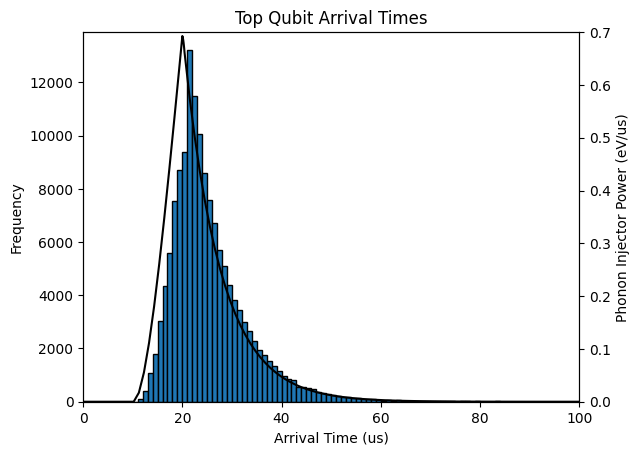

In [32]:
fig, ax1 = plt.subplots()

# Define bins
bins = np.arange(0, 121, 1)
ax1.hist(df[top_mask]['globalTime'] / 1e3, bins=bins, edgecolor='black')
ax1.set_xlim(0, 100)

# Axis labels
ax1.set_xlabel('Arrival Time (us)')
ax1.set_ylabel('Frequency')

ax2 = ax1.twinx()  # instantiate a second Axes that shares the same x-axis

color = 'black'
ax2.set_ylabel('Phonon Injector Power (eV/us)')
ax2.plot(df2["t"], df2["P"], color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 0.7)

plt.title('Top Qubit Arrival Times')
plt.show()

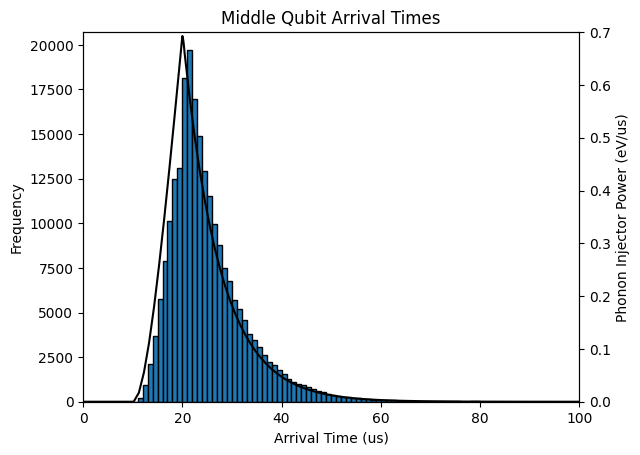

In [33]:
fig, ax1 = plt.subplots()

# Define bins
bins = np.arange(0, 121, 1)
ax1.hist(df[middle_mask]['globalTime'] / 1e3, bins=bins, edgecolor='black')
ax1.set_xlim(0, 100)

# Axis labels
ax1.set_xlabel('Arrival Time (us)')
ax1.set_ylabel('Frequency')

ax2 = ax1.twinx()  # instantiate a second Axes that shares the same x-axis

color = 'black'
ax2.set_ylabel('Phonon Injector Power (eV/us)')
ax2.plot(df2["t"], df2["P"], color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 0.7)

plt.title('Middle Qubit Arrival Times')

plt.show()

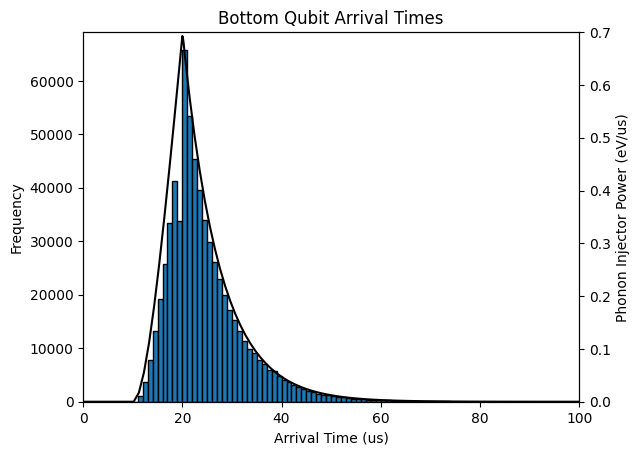

In [34]:
fig, ax1 = plt.subplots()

# Define bins
bins = np.arange(0, 121, 1)
ax1.hist(df[bottom_mask]['globalTime'] / 1e3, bins=bins, edgecolor='black')
ax1.set_xlim(0, 100)

# Axis labels
ax1.set_xlabel('Arrival Time (us)')
ax1.set_ylabel('Frequency')

ax2 = ax1.twinx()  # instantiate a second Axes that shares the same x-axis

color = 'black'
ax2.set_ylabel('Phonon Injector Power (eV/us)')
ax2.plot(df2["t"], df2["P"], color=color)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 0.7)

plt.title('Bottom Qubit Arrival Times')

plt.show()

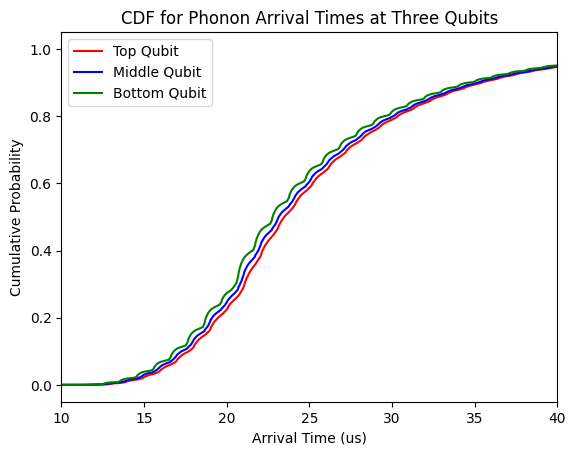

In [37]:
n_top = len(df[top_mask])
n_middle = len(df[middle_mask])
n_bottom = len(df[bottom_mask])

top_cdf = np.arange(0, n_top + 1) / n_top
middle_cdf = np.arange(0, n_middle + 1) / n_middle
bottom_cdf = np.arange(0, n_bottom + 1) / n_bottom

plt.plot([0] + sorted(df[top_mask]['globalTime'] / 1e3), top_cdf, label='Top Qubit', color='red')
plt.plot([0] + sorted(df[middle_mask]['globalTime'] / 1e3), middle_cdf, label='Middle Qubit', color='blue')
plt.plot([0] + sorted(df[bottom_mask]['globalTime'] / 1e3), bottom_cdf, label='Bottom Qubit', color='green')

plt.title('CDF for Phonon Arrival Times at Three Qubits')
plt.xlabel('Arrival Time (us)')
plt.ylabel('Cumulative Probability')

plt.xlim(10, 40)
plt.legend()
plt.show()